## Wind Resource Assessment on Svalbard Using CARRA Data

"The governor of Svalbard is considering an wind farm to reduce diesel consumption. You have been asked to evaluate several potential sites using CARRA reanalysis."

### Objectives

In this exercise you will:

1. Visualise near-surface wind conditions from CARRA.
2. Produce maps of the study area.
3. Calculate wind speed from the wind vector components.
4. Characterise the wind climate using a Weibull distribution.
5. Estimate wind power density.
6. Assess whether the location may be suitable for wind energy production.

Dataset:
- CARRA GRIB file
- Region: West of Svalbard

In [1]:
import xarray as xr
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from scipy.stats import weibull_min
from scipy.special import gamma

import matplotlib.dates as mdates

### Task 1

Open the CARRA nc file and investigate its contents.

Questions:

1. What variables are available?
2. What projection is used?
3. What is the spatial resolution?
4. What time period is covered by the dataset?


In [38]:
# Carra
# ds = xr.open_dataset(
#     "carra.grib",
#     engine="cfgrib"
# )
file = '/Users/irms/Library/CloudStorage/OneDrive-UniversityofBergen/UniB/UNIS/teaching/excersises/weibull/point_timeseries.nc'
# file = '/Volumes/NO NAME/UNIS/point_timeseries.nc'
# file = '/Users/irms/Library/CloudStorage/OneDrive-UniversityofBergen/UniB/UNIS/teaching/excersises/CARRA.nc'
# file = 'your file path'
ds = xr.open_dataset(file)
# ds.longitude.value
ds
# print(float(ds.latitude.compute()))
# print(float(ds.longitude.compute()))

<xarray.Dataset> Size: 40kB
Dimensions:            (valid_time: 768)
Coordinates:
  * valid_time         (valid_time) datetime64[ns] 6kB 2025-02-08T01:00:00 .....
    expver             (valid_time) <U4 12kB ...
    heightAboveGround  float64 8B ...
    latitude           float64 8B ...
    longitude          float64 8B ...
Data variables:
    pres               (valid_time) float32 3kB ...
    r                  (valid_time) float32 3kB ...
    ciwc               (valid_time) float32 3kB ...
    clwc               (valid_time) float32 3kB ...
    t                  (valid_time) float32 3kB ...
    wdir               (valid_time) float32 3kB ...
    ws                 (valid_time) float32 3kB ...
Attributes:
    GRIB_centre:             enmi
    GRIB_centreDescription:  Oslo
    GRIB_subCentre:          255
    Conventions:             CF-1.7
    institution:             Oslo
    history:                 2025-11-13T09:29 GRIB to CDM+CF via cfgrib-0.9.1...

In [ ]:
# ws_obs = df["VH1_10_min"].dropna()
# print(ws.describe())


In [99]:
print(ds['ws'].attrs)

{'GRIB_paramId': 10, 'GRIB_dataType': 'fc', 'GRIB_numberOfPoints': 1356561, 'GRIB_typeOfLevel': 'heightAboveGround', 'GRIB_stepUnits': 1, 'GRIB_stepType': 'instant', 'GRIB_gridType': 'lambert', 'GRIB_uvRelativeToGrid': 1, 'GRIB_DxInMetres': 2500.0, 'GRIB_DyInMetres': 2500.0, 'GRIB_LaDInDegrees': 72.0, 'GRIB_Latin1InDegrees': 72.0, 'GRIB_Latin2InDegrees': 72.0, 'GRIB_LoVInDegrees': 324.0, 'GRIB_NV': 0, 'GRIB_Nx': 1069, 'GRIB_Ny': 1269, 'GRIB_cfName': 'unknown', 'GRIB_cfVarName': 'ws', 'GRIB_gridDefinitionDescription': 'Lambert conformal', 'GRIB_iScansNegatively': 0, 'GRIB_jPointsAreConsecutive': 0, 'GRIB_jScansPositively': 1, 'GRIB_latitudeOfFirstGridPointInDegrees': 55.81, 'GRIB_latitudeOfSouthernPoleInDegrees': 0.0, 'GRIB_longitudeOfFirstGridPointInDegrees': 302.903, 'GRIB_longitudeOfSouthernPoleInDegrees': 0.0, 'GRIB_missingValue': 3.4028234663852886e+38, 'GRIB_name': 'Wind speed', 'GRIB_shortName': 'ws', 'GRIB_units': 'm s**-1', 'long_name': 'Wind speed', 'units': 'm s**-1', 'standa

In [100]:
list(ds.data_vars)

['pres', 'r', 'ciwc', 'clwc', 't', 'wdir', 'ws']

### Task 2

Calculate wind speed from the horizontal wind components.

Questions:

1. What is the mean wind speed in the domain?
2. What is the maximum wind speed?
3. Why is wind speed calculated from both u and v components?

In [40]:
ds

<xarray.Dataset> Size: 40kB
Dimensions:            (valid_time: 768)
Coordinates:
  * valid_time         (valid_time) datetime64[ns] 6kB 2025-02-08T01:00:00 .....
    expver             (valid_time) <U4 12kB ...
    heightAboveGround  float64 8B ...
    latitude           float64 8B ...
    longitude          float64 8B ...
Data variables:
    pres               (valid_time) float32 3kB ...
    r                  (valid_time) float32 3kB ...
    ciwc               (valid_time) float32 3kB ...
    clwc               (valid_time) float32 3kB ...
    t                  (valid_time) float32 3kB ...
    wdir               (valid_time) float32 3kB ...
    ws                 (valid_time) float32 3kB ...
Attributes:
    GRIB_centre:             enmi
    GRIB_centreDescription:  Oslo
    GRIB_subCentre:          255
    Conventions:             CF-1.7
    institution:             Oslo
    history:                 2025-11-13T09:29 GRIB to CDM+CF via cfgrib-0.9.1...

In [39]:
# ws = np.sqrt(ds["u10"]**2 + ds["v10"]**2)
# ws = ds['ws'][:,0,:,:]
# ws.attrs["units"] = "m s-1"
ws=ds['ws']
ws

<xarray.DataArray 'ws' (valid_time: 768)> Size: 3kB
[768 values with dtype=float32]
Coordinates:
  * valid_time         (valid_time) datetime64[ns] 6kB 2025-02-08T01:00:00 .....
    expver             (valid_time) <U4 12kB ...
    heightAboveGround  float64 8B ...
    latitude           float64 8B ...
    longitude          float64 8B ...
Attributes: (12/34)
    GRIB_paramId:                             10
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      1356561
    GRIB_typeOfLevel:                         heightAboveGround
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_name:                                Wind speed
    GRIB_shortName:                           ws
    GRIB_units:                               m s**-1
    long_name:                                Wind speed
    units:                                    m s**-1
    standard_name:                            unknown

### Task 3

Create a map showing:

- Map containing Svalbard
- Point of model output

/opt/homebrew/anaconda3/lib/python3.12/site-packages/shapely/creation.py:460: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, typ, out=out, **kwargs)
/opt/homebrew/anaconda3/lib/python3.12/site-packages/shapely/creation.py:460: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, typ, out=out, **kwargs)


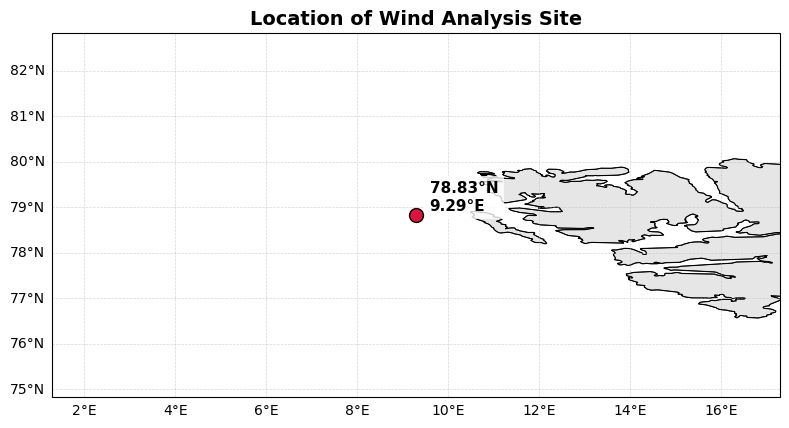

In [17]:
# Your selected point
lat0 = float(ds.latitude.compute())
lon0 = float(ds.longitude.compute())

fig = plt.figure(figsize=(8, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# Nice background
ax.add_feature(
    cfeature.LAND,
    facecolor="0.9",
    edgecolor="black",
    linewidth=0.5,
    zorder=1,
)

ax.add_feature(
    cfeature.OCEAN,
    facecolor="white",
    zorder=0,
)

ax.coastlines(
    resolution="10m",
    linewidth=0.8,
)

# Extent around location
ax.set_extent([
    lon0 - 8,
    lon0 + 8,
    lat0 - 4,
    lat0 + 4
])

# Plot point
ax.plot(
    lon0,
    lat0,
    marker="o",
    markersize=10,
    color="crimson",
    markeredgecolor="black",
    markeredgewidth=1,
    transform=ccrs.PlateCarree(),
    zorder=10,
)

# Annotation
ax.text(
    lon0 + 0.3,
    lat0 + 0.1,
    f"{lat0:.2f}°N\n{lon0:.2f}°E",
    fontsize=11,
    weight="bold",
    transform=ccrs.PlateCarree(),
    bbox=dict(
        facecolor="white",
        alpha=0.8,
        edgecolor="none"
    ),
)

# Gridlines
gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.5,
    linestyle="--",
    alpha=0.5,
)

gl.top_labels = False
gl.right_labels = False

plt.title(
    "Location of Wind Analysis Site",
    fontsize=14,
    weight="bold",
)

plt.tight_layout()
plt.show()

### Task 4

Choose a location on eastern Svalbard and extract a wind speed time series.

Questions:

1. What are the coordinates?
2. Why might this location be interesting for wind energy production?

In [ ]:
# haversine function to calculate closest points
def nearest_grid_point(ds, lat0, lon0):

    R = 6371.0  # Earth radius [km]

    lat1 = np.radians(lat0)
    lon1 = np.radians(lon0)

    lat2 = np.radians(ds.latitude.values)
    lon2 = np.radians(ds.longitude.values)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat/2)**2 +
        np.cos(lat1) *
        np.cos(lat2) *
        np.sin(dlon/2)**2
    )

    c = 2 * np.arctan2(
        np.sqrt(a),
        np.sqrt(1-a)
    )

    distance = R * c

    iy, ix = np.unravel_index(
        np.argmin(distance),
        distance.shape
    )

    return iy, ix

# iy, ix = nearest_grid_point(ds, 78.25, 23.5)

# point = ds.isel(y=iy, x=ix)

### Task 5

Create a wind speed time series.

Questions:

1. Does the location appear windy?
2. Are there calm periods?
3. Is there evidence of storm events?

In [18]:
ds = ds.sortby("valid_time")

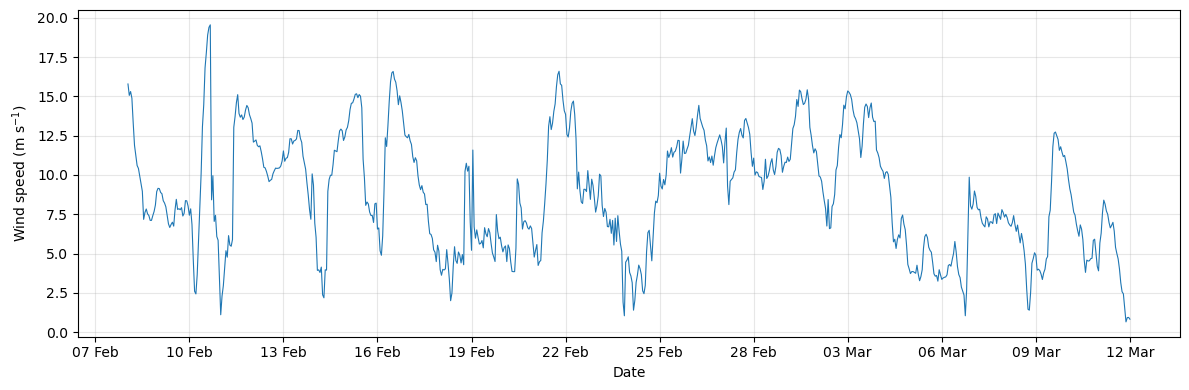

In [19]:
fig, ax = plt.subplots(figsize=(12,4))

ax.plot(ds.valid_time, ds.ws, lw=0.8)

# One tick every 3 days
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax.set_ylabel("Wind speed (m s$^{-1}$)")
ax.set_xlabel("Date")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Task 6

Produce a histogram of wind speed.

Questions:

1. Is the distribution symmetric?
2. At which wind speed does the histogram peak?
3. Are high wind speeds common or rare?

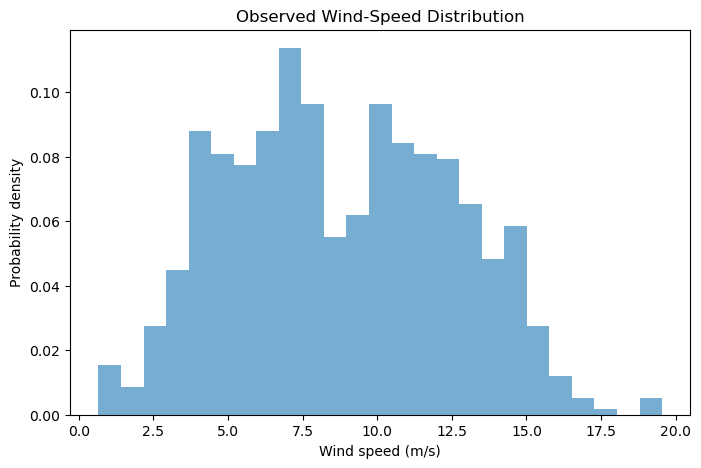

In [20]:
windspeed = ds['ws'][~np.isnan(ds['ws'])]

plt.figure(figsize=(8,5))

plt.hist(
    windspeed,
    bins=25,
    density=True,
    alpha=0.6
)

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Probability density")

plt.title("Observed Wind-Speed Distribution")

plt.show()

## 1. The Weibull Probability Density Function (PDF)

The Weibull distribution is commonly used to describe wind speed frequencies.

$$
f(U) =
\frac{k}{A}
\left(\frac{U}{A}\right)^{k-1}
\exp\left[-\left(\frac{U}{A}\right)^k\right]
$$

where:

- $U$ = wind speed (m s$^{-1}$)
- $A$ = scale parameter (m s$^{-1}$)
- $k$ = shape parameter
- $f(U)$ = probability density

### Components of the equation

The probability density function consists of three parts:

$$
\frac{k}{A}
$$

A scaling factor that ensures the total probability equals 1.

$$
\left(\frac{U}{A}\right)^{k-1}
$$

Controls the behaviour at low wind speeds and influences the shape of the distribution.

$$
\exp\left[-\left(\frac{U}{A}\right)^k\right]
$$

An exponential decay term that reduces the probability of very high wind speeds.

### Important properties

The Weibull distribution is defined only for:

$$
U \ge 0
$$

which is physically appropriate because wind speeds cannot be negative.

The total area under the curve is:

$$
\int_0^\infty f(U)\,dU = 1
$$

meaning that all possible wind speeds together account for 100% of the probability.

### Physical interpretation

The Weibull probability density function answers the question:

> How frequently do different wind speeds occur?

For a given wind speed $U$:

- a larger value of $f(U)$ indicates that wind speed occurs more frequently;
- a smaller value of $f(U)$ indicates that wind speed is relatively rare.

The overall shape of the distribution is controlled by:

- **Scale parameter ($A$):** determines how windy the site is.
- **Shape parameter ($k$):** determines how variable the wind speeds are.


### Task 7

Fit a Weibull distribution to the wind-speed data.

Questions:

1. What are the fitted values of A and k?
2. What does the scale parameter A represent?
3. What does the shape parameter k represent?
4. Is the wind climate highly variable or relatively persistent?

In [21]:
k, loc, A = weibull_min.fit(
    windspeed,
    floc=0
)

print(f"A = {A:.2f} m/s")
print(f"k = {k:.2f}")

A = 9.90 m/s
k = 2.56


### Task 8

Compare the observed wind-speed distribution and the fitted Weibull distribution.

Questions:

1. Does the Weibull provide a good fit?
2. Where do the largest differences occur?
3. What meteorological reasons could explain these differences?

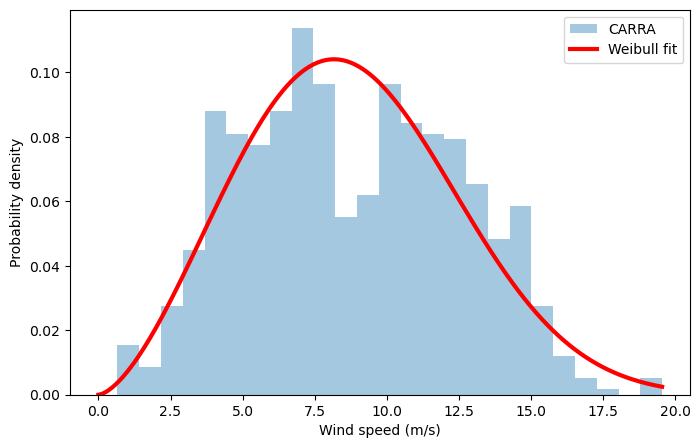

In [22]:
x = np.linspace(
    0,
    windspeed.max(),
    300
)

pdf = weibull_min.pdf(
    x,
    k,
    scale=A
)

plt.figure(figsize=(8,5))

plt.hist(
    windspeed,
    bins=25,
    density=True,
    alpha=0.4,
    label="CARRA"
)

plt.plot(
    x,
    pdf,
    "r",
    linewidth=3,
    label="Weibull fit"
)

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Probability density")

plt.legend()

plt.show()

### Task 9

Estimate the wind power density.

The wind power density is

P = 0.5 ρ A³ Γ(1+3/k)

Assume:

ρ = 1.225 kg m⁻³

Questions:

1. What is the estimated wind power density?
2. How does it compare with typical wind farm sites?
3. Would this location be suitable for wind energy production?

In [23]:
rho = 1.225

wpd = (
    0.5
    * rho
    * A**3
    * gamma(1 + 3/k)
)

print(f"Wind power density = {wpd:.1f} W m^-2")

Wind power density = 645.0 W m^-2


### Task 10

Interpret your results.

Typical values:

| Resource quality | Wind power density |
|-----------------|-------------------|
| Poor | <100 W m⁻² |
| Fair | 100–300 W m⁻² |
| Good | 300–500 W m⁻² |
| Excellent | >500 W m⁻² |

Questions:

1. Into which category does your location fall?
2. What are the strengths and weaknesses of the site?
3. What additional information would be required before building a wind farm?

## Discussion

Summarise:

1. The local wind climate.
2. The Weibull parameters obtained.
3. The estimated wind power density.
4. Whether the location appears suitable for wind energy.
5. The advantages and limitations of using reanalysis/model data (CARRA) instead of observations.

## Why Not Just Use the Mean Wind Speed?

A common way to describe a windy location is by its average wind speed.

For example:

- Site A: mean wind speed = 8 m/s
- Site B: mean wind speed = 8 m/s

At first glance, these sites appear identical.

However, wind turbines do not produce power proportional to wind speed. Wind power is approximately proportional to the cube of wind speed:

P ∝ U³

This means that:

- Doubling the wind speed increases power by a factor of 8.
- A few strong winds can contribute a large fraction of total energy production.

Therefore, two sites with the same average wind speed may have very different wind energy potential.

### Observations
Now use obs from Adventdalen, make a histrogram, fi the Weibull distribution and compare to the offshore location. \

In [2]:
# Observations Adventdalen
file = '/Users/irms/Downloads/Adventdalen_Hour.dat'

with open(file, "r", errors="ignore") as f:
    for i in range(20):
        print(f.readline().rstrip())

# VH1_mps_MaxMaximum gust during interval (m/s)
# VH1_10_min10-minute average wind speed (m/s)
# VH1_mps_midMean wind speed during interval (m/s)
# VR1_gr_framh Mean wind direction (°)

# LT = temperature (Lufttemperatur or temperature sensor)
# LF = relative humidity (Luftfuktighet)
# AT = atmospheric pressure
# VH = wind speed (Vindhastighet)
# VR = wind direction (Vindretning)
# gr = degrees (°)
# prst = percent (%)
# mps = metres per second (m/s)
# mbar = millibar (hPa)

"TOA5","Adventdalen_New","CR1000","21598","CR1000.Std.15","CPU:853.CR1","23652","Time"
"TIMESTAMP","RECORD","ID","LT1_gr_C_Max","LT1_gr_C_Min","LT1_gr_C_Avg","LT2_gr_C_Max","LT2_gr_C_Min","LT2_gr_C_Avg","LT3_gr_C_Max","LT3_gr_C_Min","LT3_gr_C_Avg","LF1_prst_Max","LF1_prst_Avg","LT4_gr_C_Max","LT4_gr_C_Min","LT4_gr_C_Avg","LF2_prst_Max","LF2_prst_Avg","AT_mbar","VH1_mps_Max","VH1_10_min","VH1_mps_mid","VR1_gr_framh","VH2_sek_Max","VH2_10_min","VH2_mps_mid","VR2_gr_framh","Batt_V_Min"
"TS","RN","","","","","","","","","","","","","","","","","","","","","","Deg","","","","Deg",""
"","","Smp","Max","Min","Avg","Max","Min","Avg","Max","Min","Avg","Max","Avg","Max","Min","Avg","Max","Avg","Smp","Max","Smp","WVc","WVc","Max","Smp","WVc","WVc","Min"
"2016-01-01 00:00:00",4717,853,5.747,3.524,4.685,6.002,4.025,5.165,5.663,3.442,4.646,77.87,70.65,6.295,4.615,5.569,70.92,64.27,1007.052,6.697,2.675,2.979,123.9,7.742,2.791,3.53,126.9,13.76
"2016-01-01 01:00:00",4718,853,5.381,4.032,4.678,5.772,4.7

In [3]:
df = pd.read_csv(
    file,
    skiprows=[0, 2, 3],  # skip metadata, units, and type rows
    parse_dates=["TIMESTAMP"]
)

print(df.head())
print(df.columns)

            TIMESTAMP  RECORD   ID  LT1_gr_C_Max  LT1_gr_C_Min  LT1_gr_C_Avg  \
0 2016-01-01 00:00:00    4717  853         5.747         3.524         4.685   
1 2016-01-01 01:00:00    4718  853         5.381         4.032         4.678   
2 2016-01-01 02:00:00    4719  853         5.492         2.993         4.352   
3 2016-01-01 03:00:00    4720  853         4.866         2.576         3.651   
4 2016-01-01 04:00:00    4721  853         5.045         3.376         4.086   

   LT2_gr_C_Max  LT2_gr_C_Min  LT2_gr_C_Avg  LT3_gr_C_Max  ...   AT_mbar  \
0         6.002         4.025         5.165         5.663  ...  1007.052   
1         5.772         4.787         5.338         5.241  ...  1007.426   
2         5.950         4.358         5.271         5.411  ...  1007.593   
3         5.886         3.469         5.087         4.728  ...  1007.763   
4         6.321         4.074         5.288         4.882  ...  1008.046   

   VH1_mps_Max  VH1_10_min  VH1_mps_mid  VR1_gr_framh  VH2_sek

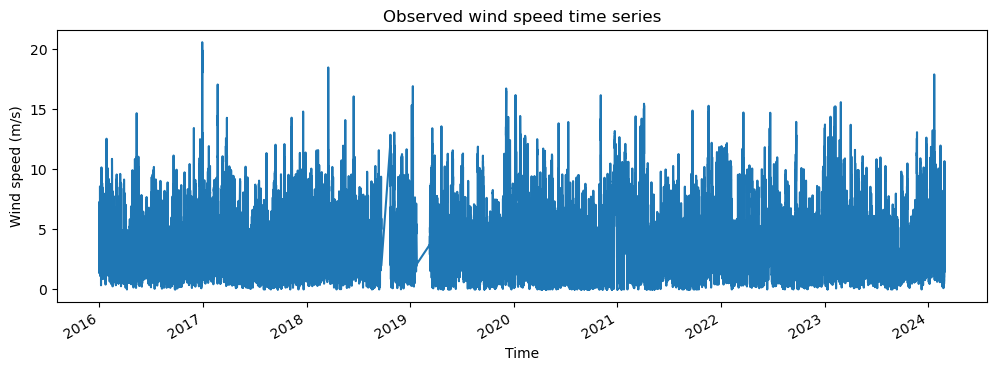

In [4]:
df["TIMESTAMP"] = pd.to_datetime(df["TIMESTAMP"])

obs_ws = df.set_index("TIMESTAMP")["VH1_mps_mid"]

plt.figure(figsize=(12,4))

obs_ws.plot()

plt.xlabel("Time")
plt.ylabel("Wind speed (m/s)")
plt.title("Observed wind speed time series")

plt.show()

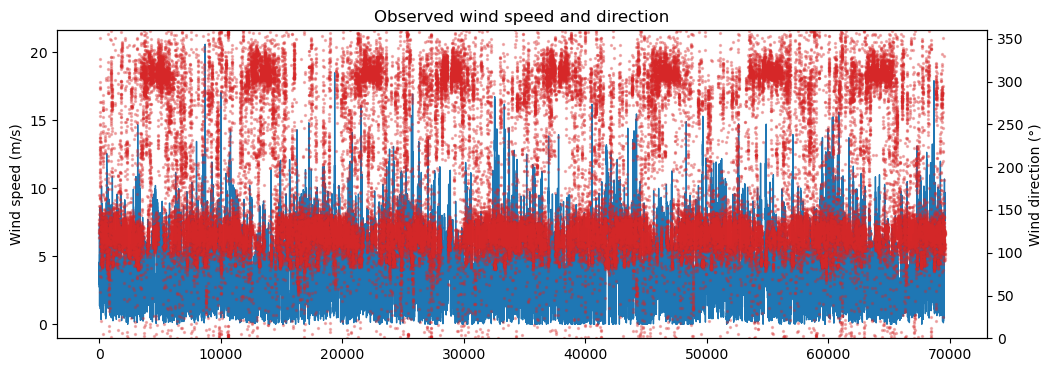

In [43]:
fig, ax1 = plt.subplots(figsize=(12,4))

ax1.plot(df.index, df["VH1_mps_mid"],
         color="tab:blue", lw=1)
ax1.set_ylabel("Wind speed (m/s)")

ax2 = ax1.twinx()
ax2.scatter(df.index, df["VR1_gr_framh"],
            s=2, color="tab:red", alpha=0.3)
ax2.set_ylabel("Wind direction (°)")
ax2.set_ylim(0, 360)

plt.title("Observed wind speed and direction")
plt.show()

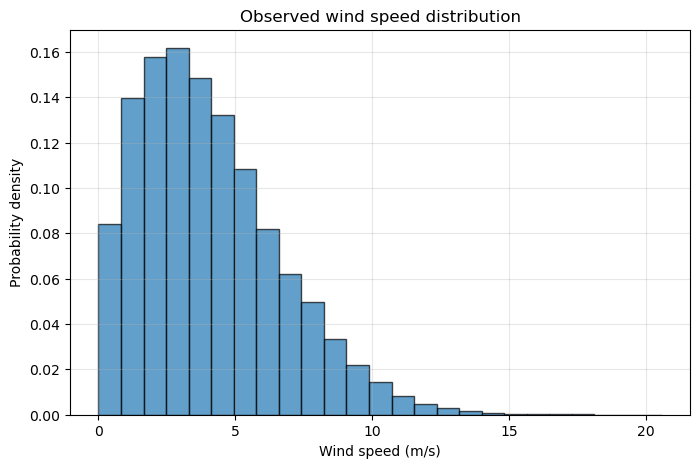

In [32]:
obs_ws = df["VH1_mps_mid"].dropna()

plt.figure(figsize=(8,5))

plt.hist(
    obs_ws,
    bins=25,
    density=True,
    alpha=0.7,
    edgecolor="black"
)

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Probability density")
plt.title("Observed wind speed distribution")
plt.grid(alpha=0.3)

plt.show()

In [ ]:
k_obs, loc_obs, A_obs = weibull_min.fit(
    obs_ws,
    floc=0
)

print("Weibull fit Observations")
print(f"k = {k_obs:.2f}")
print(f"A = {A_obs:.2f} m/s")

print('Weibull fit model')
print(f"A = {A:.2f} m/s")
print(f"k = {k:.2f}")



Weibull fit Observations
k = 1.56
A = 4.49 m/s
Weibull fir model
A = 9.90 m/s
k = 2.56


Shape parameter k

The shape parameter describes how variable the winds are.

- k ≈ 1: very irregular, lots of calm periods and occasional strong winds
- k ≈ 2: typical wind climate
- k > 3: fairly steady winds

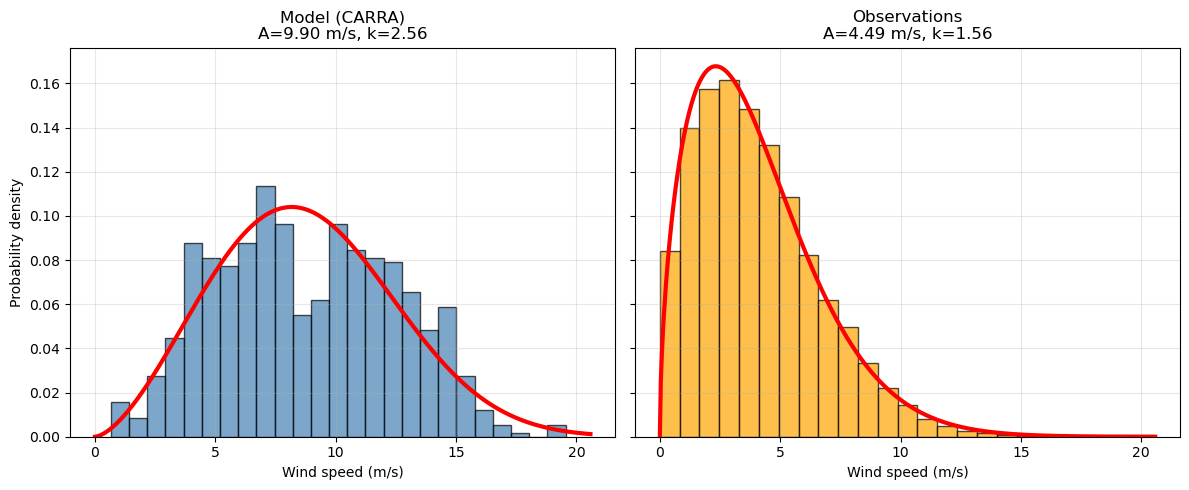

In [ ]:

# Common axes
xmax = max(obs_ws.max(), ws.max())
x = np.linspace(0, xmax, 500)

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# --------------------------------------------------
# Left: Model (CARRA)
# --------------------------------------------------
ax[0].hist(
    ws,
    bins=25,
    density=True,
    alpha=0.7,
    color="steelblue",
    edgecolor="black"
)

ax[0].plot(
    x,
    weibull_min.pdf(x, k, scale=A),
    "r-",
    lw=3
)

ax[0].set_title(
    f"Model (CARRA)\nA={A:.2f} m/s, k={k:.2f}"
)
ax[0].set_xlabel("Wind speed (m/s)")
ax[0].set_ylabel("Probability density")
ax[0].grid(alpha=0.3)

# --------------------------------------------------
# Right: Observations
# --------------------------------------------------
ax[1].hist(
    obs_ws,
    bins=25,
    density=True,
    alpha=0.7,
    color="orange",
    edgecolor="black"
)

ax[1].plot(
    x,
    weibull_min.pdf(x, k_obs, scale=A_obs),
    "r-",
    lw=3
)

ax[1].set_title(
    f"Observations\nA={A_obs:.2f} m/s, k={k_obs:.2f}"
)
ax[1].set_xlabel("Wind speed (m/s)")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Obs peak density ~ 0.16 
# CARRA peak density ~ 0.08